In [20]:
df = pd.read_csv("books_data.csv")

print("Dataset loaded successfully!")

print(df.head())

Dataset loaded successfully!
                               Book Name    Price Availability
0                   A Light in the Attic  Â£51.77     In stock
1                     Tipping the Velvet  Â£53.74     In stock
2                             Soumission  Â£50.10     In stock
3                          Sharp Objects  Â£47.82     In stock
4  Sapiens: A Brief History of Humankind  Â£54.23     In stock


In [21]:
print("Dataset Information:")
print(df.info())

print("\nDataset Shape:")
print(df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDataset Statistics:")
print(df.describe(include="all"))

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Book Name     20 non-null     object
 1   Price         20 non-null     object
 2   Availability  20 non-null     object
dtypes: object(3)
memory usage: 612.0+ bytes
None

Dataset Shape:
(20, 3)

Missing Values:
Book Name       0
Price           0
Availability    0
dtype: int64

Dataset Statistics:
                   Book Name    Price Availability
count                     20       20           20
unique                    20       20            1
top     A Light in the Attic  Â£51.77     In stock
freq                       1        1           20


In [22]:
df["Price"] = (
    df["Price"]
    .astype(str)
    .str.extract(r"(\d+\.?\d*)")[0]
)

df["Price"] = pd.to_numeric(df["Price"], errors="coerce")

df = df.dropna(subset=["Price", "Book Name"])

print(df[["Book Name", "Price"]].head())

                               Book Name  Price
0                   A Light in the Attic  51.77
1                     Tipping the Velvet  53.74
2                             Soumission  50.10
3                          Sharp Objects  47.82
4  Sapiens: A Brief History of Humankind  54.23


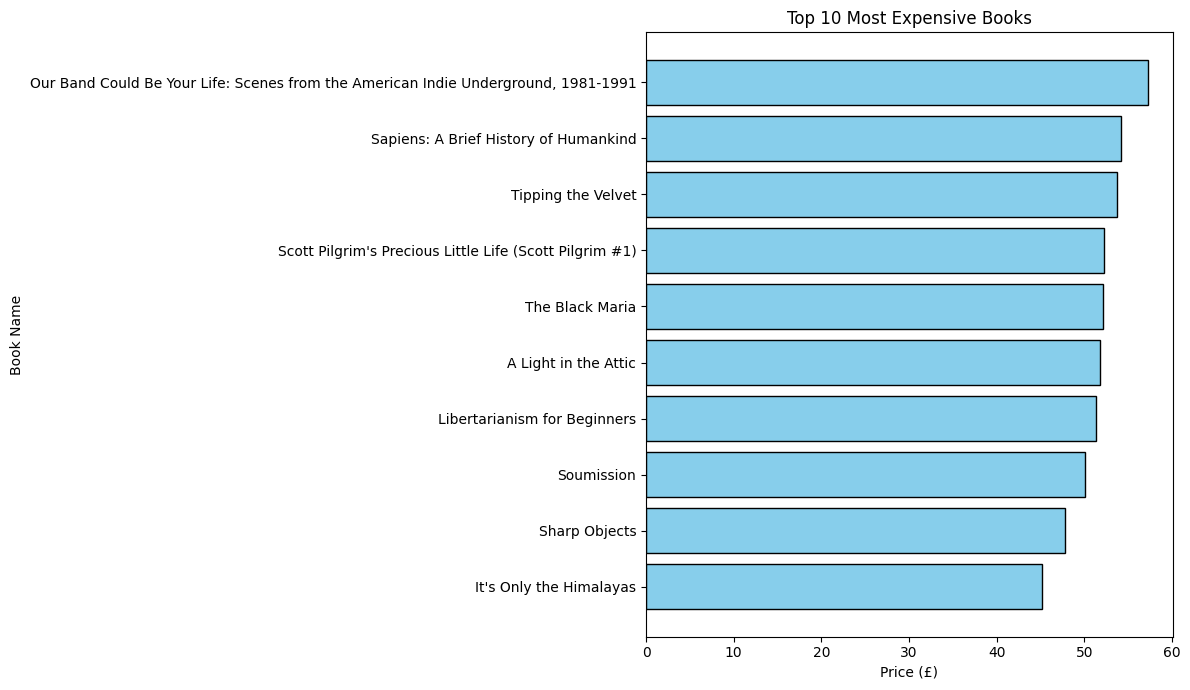

In [23]:
top_books = df.nlargest(10, "Price")

plt.figure(figsize=(12, 7))

plt.barh(
    top_books["Book Name"],
    top_books["Price"],
    color="skyblue",
    edgecolor="black"
)

plt.xlabel("Price (£)")
plt.ylabel("Book Name")
plt.title("Top 10 Most Expensive Books")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

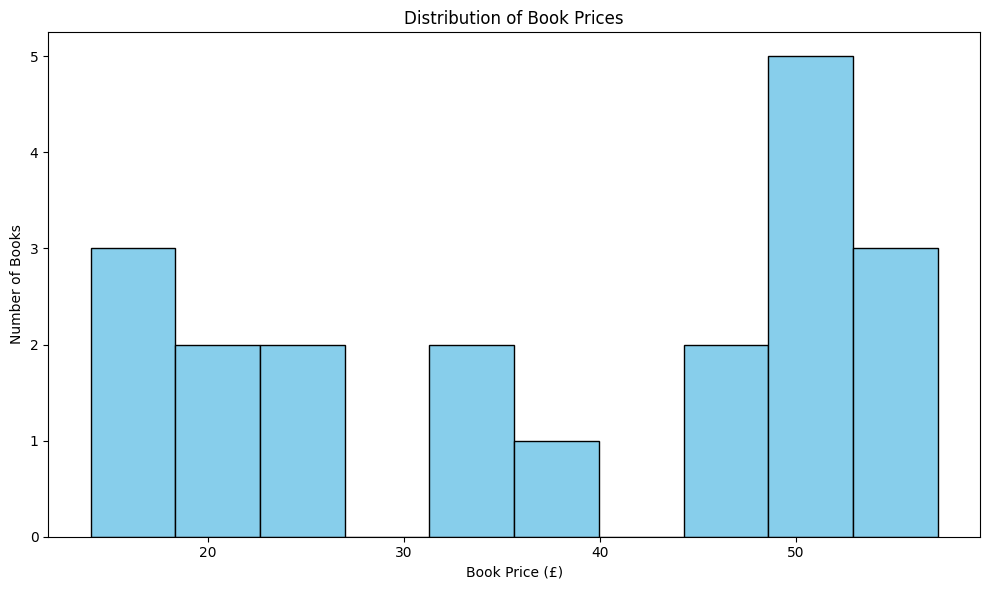

In [24]:
plt.figure(figsize=(10, 6))

plt.hist(
    df["Price"],
    bins=10,
    color="skyblue",
    edgecolor="black"
)

plt.xlabel("Book Price (£)")
plt.ylabel("Number of Books")
plt.title("Distribution of Book Prices")

plt.tight_layout()
plt.show()

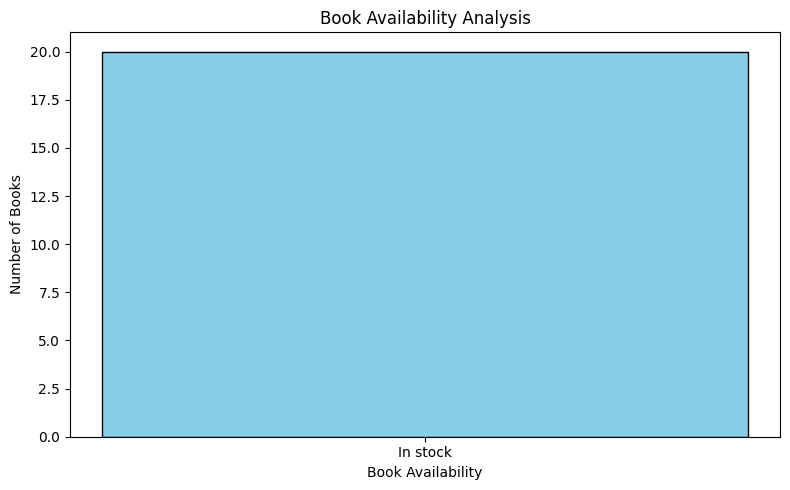

In [26]:
availability_counts = df["Availability"].value_counts()

plt.figure(figsize=(8, 5))

plt.bar(
    availability_counts.index,
    availability_counts.values,
    color="skyblue",
    edgecolor="black",
    width=0.5
)

plt.xlabel("Book Availability")
plt.ylabel("Number of Books")
plt.title("Book Availability Analysis")

plt.tight_layout()
plt.show()

In [27]:
print("DATA ANALYSIS INSIGHTS")

print("Total Books:", len(df))

print("Average Book Price: £", round(df["Price"].mean(), 2))

print("Highest Book Price: £", df["Price"].max())

print("Lowest Book Price: £", df["Price"].min())

print("\nBook Availability:")
print(df["Availability"].value_counts())

DATA ANALYSIS INSIGHTS
Total Books: 20
Average Book Price: £ 38.05
Highest Book Price: £ 57.25
Lowest Book Price: £ 13.99

Book Availability:
Availability
In stock    20
Name: count, dtype: int64


In [28]:
plt.savefig("top_10_books.png")

<Figure size 640x480 with 0 Axes>